# 02 Analysis: Where Is Toronto Construction Demand Growing?

**Business task:** identify where in Toronto construction activity is growing, what kind of work it is, and how quickly permits move, so a building supply company's sales team can focus territory and product mix on the strongest demand.

## Findings summary

**Analysis set:** 191,381 permits (cancelled permits and trade permits tied to a building permit excluded), applications from January 2017 to September 2026. Trends use full years 2017 to 2025. Values are declared costs in nominal dollars, **not adjusted for inflation**.

**Q1. Where is activity concentrated and growing?**
- City-wide, permit counts were almost flat: **+1.4%** from 2022-2023 to 2024-2025. Growth is local, not city-wide.
- Fastest-growing FSAs (at least 50 permits in the base window): **M3C +74%** (205 to 357 permits), **M4A +57%**, **M9A +53%**.
- **M3C** is the only FSA that is both a top grower and a top value area: second-highest recent declared value ($1.64B) and 90 new construction permits in 2024-2025.
- Value is concentrated: the **top 10 of 98 FSAs hold 43%** of 2024-2025 declared value, led by M4S ($2.09B), M3C, M2M and M5A.
- Some value rankings rest on one project: the largest single permit is 58% of M1S's recent value and 70% of M1P's.
- Largest decline: **M2N, -43%** (1,236 to 703 permits).

**Q2. What kind of work is it?**
- Residential is **69% of permits but 35% of declared value**. New construction is **10% of permits but 64% of value**.
- Renovation and alteration is the largest category by count (45%), and its share grew from 41% of permits in 2017 to 47-48% in 2022-2024.
- Residential's share of value fell from 41-50% (2017-2022) to 20-31% (2023-2025), while its share of permits stayed at 67-68%. Recent value growth has come from non-residential and mixed-use work.

**Q3. How quickly do permits move?** (median days from application to issuance, issued non-revised permits)
- Building services 4, Addition 26, Renovation 27, Demolition 57, **New construction 83**. A quarter of new construction permits take 237 days or more.
- By permit type: New Houses 71 days, New Building **389 days**. Mixed-use projects: 285 days.
- For renovations, FSA medians fall in a narrow 15 to 38 day range, so location matters little. For new construction they range from 20 to 1,738 days; the M2L figure comes from one development: about 200 New Houses permits applied for in 2019, one per unit of a stacked back-to-back townhouse project, each issued roughly 4.8 years later. It reflects one project, not how fast M2L permits move in general.
- The yearly median rose from 19 days (2017) to 32 (2022), then fell to 19-22 for 2024-2025 applications. Because 5-7% of 2024-2025 permits are not yet issued, part of that improvement may be waiting bias.

**Q4. How have volumes and values changed?**
- Permit counts fell from 23,804 (2017) to a low of 16,246 (2023), with a 23% drop in 2020. They recovered to 18,109 in 2025, still about 24% below 2017.
- Declared value rose from $6.8B (2017) to **$16.9B (2025)** in nominal dollars: fewer permits, but larger ones.
- Clear seasonality: **May to August are the busiest months** (about 7-12% above an average month); **December and January are the quietest** (15-19% below).

**Caveats:** declared costs are self-reported and not inflation-adjusted; value rankings can hinge on a single project; 22% of New Building permits have no postal code, so the FSA view under-counts new buildings; recent approval times are biased low.

## How demand is measured

Decisions made before any numbers were seen, so they cannot be tuned to give a nicer answer:

| Decision | Choice | Why |
|---|---|---|
| Cancelled permits | Excluded | A cancelled permit is unlikely to lead to material purchases |
| Trade permits tied to a building permit (`is_related_permit`) | Excluded from counts | Otherwise one project counts several times (plumbing, HVAC, drains). They are already covered by the main permit |
| Declared value | Only rows with `cost_declared` | 0 and placeholder costs mean "not declared", not "free" |
| Years compared | Full calendar years only | The current year is partial and would look like a drop |
| Growth | Last two full years vs the two years before | Two-year windows smooth out one-off big projects |
| Small areas | FSAs need at least 50 permits in the base window to get a growth rate | Growth from 5 to 10 permits is "+100%" but means little |
| Approval time | Issued, non-revised permits; median, not mean | Approval days are heavily right-skewed; a few multi-year permits would drag the mean |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN = ROOT / "data" / "clean"
TABLES = ROOT / "outputs" / "summary_tables"
FIGS = ROOT / "outputs" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.1f}".format)

# Chart style: one consistent, colorblind-checked palette, used in a fixed
# order so a category keeps its colour across every chart.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def save_table(df, name):
    # Every summary table is saved for Tableau and for the README.
    df.to_csv(TABLES / f"{name}.csv", index=True)
    print(f"saved outputs/summary_tables/{name}.csv ({len(df):,} rows)")

## 1. Load the clean data and define the analysis set

In [2]:
date_cols = ["APPLICATION_DATE", "ISSUED_DATE", "COMPLETED_DATE", "app_year_month"]
permits = pd.read_csv(
    CLEAN / "permits_clean.csv",
    parse_dates=date_cols,
    dtype={"PERMIT_NUM": str, "REVISION_NUM": str, "project_id": str, "fsa": str, "POSTAL": str},
    low_memory=False,
)
# Make sure the flag columns are real booleans whatever pandas inferred.
for col in ["cost_declared", "is_cancelled", "is_revision", "is_related_permit"]:
    permits[col] = permits[col].astype(str).str.lower().eq("true")

print(f"Clean permits loaded: {len(permits):,}")

# The data runs to the latest daily refresh, so the last month is partial.
# Work out the last FULL month and the last FULL year from the data itself.
last_date = permits["APPLICATION_DATE"].max()
LAST_FULL_MONTH = (last_date.to_period("M") - 1).to_timestamp()
LAST_FULL_YEAR = LAST_FULL_MONTH.year if LAST_FULL_MONTH.month == 12 else LAST_FULL_MONTH.year - 1
FULL_YEARS = list(range(2017, LAST_FULL_YEAR + 1))
RECENT = [LAST_FULL_YEAR - 1, LAST_FULL_YEAR]          # e.g. 2024-2025
BASE = [LAST_FULL_YEAR - 3, LAST_FULL_YEAR - 2]        # e.g. 2022-2023

print("Latest application date:", last_date.date())
print("Last full month:        ", LAST_FULL_MONTH.strftime("%Y-%m"))
print("Full years:             ", FULL_YEARS[0], "to", FULL_YEARS[-1])
print("Growth windows:          base", BASE, "vs recent", RECENT)

Clean permits loaded: 388,263
Latest application date: 2026-10-09
Last full month:         2026-09
Full years:              2017 to 2025
Growth windows:          base [2022, 2023] vs recent [2024, 2025]


In [3]:
# The analysis set: permits that represent real, distinct demand.
demand = permits[~permits["is_cancelled"] & ~permits["is_related_permit"]].copy()

print(f"All clean permits:                {len(permits):,}")
print(f"  minus cancelled:                {permits['is_cancelled'].sum():,}")
print(f"  minus trade permits (related):  {(permits['is_related_permit'] & ~permits['is_cancelled']).sum():,}")
print(f"Demand permits:                   {len(demand):,}")
print(f"  with a declared cost:           {demand['cost_declared'].sum():,}")
print(f"  with an FSA:                    {demand['fsa'].notna().sum():,}")

# Value column that only holds declared costs, so sums and medians ignore the rest.
demand["declared_value"] = demand["est_cost"].where(demand["cost_declared"])

All clean permits:                388,263
  minus cancelled:                33,297
  minus trade permits (related):  163,585
Demand permits:                   191,381
  with a declared cost:           114,864
  with an FSA:                    179,695


## Q1. Where is permit activity concentrated and growing?

For each FSA: permits and declared value in the base and recent windows, growth in permit count, and the FSA's share of the city's recent value.

Growth is measured on **permit counts**, not value. A single tower can add hundreds of millions of dollars to one FSA in one year, which would make value growth mostly a story about one project. Value is shown alongside so both views are visible.

In [4]:
fsa_df = demand[demand["fsa"].notna() & demand["app_year"].isin(BASE + RECENT)].copy()
fsa_df["window"] = np.where(fsa_df["app_year"].isin(RECENT), "recent", "base")

fsa = fsa_df.pivot_table(index="fsa", columns="window", values="PERMIT_NUM",
                         aggfunc="count", fill_value=0)
fsa.columns = [f"permits_{c}" for c in fsa.columns]

value = fsa_df.pivot_table(index="fsa", columns="window", values="declared_value",
                           aggfunc="sum", fill_value=0)
value.columns = [f"value_{c}" for c in value.columns]

new_build = (fsa_df[(fsa_df["window"] == "recent") & (fsa_df["work_category"] == "New construction")]
             .groupby("fsa").size().rename("new_construction_recent"))

fsa = fsa.join(value).join(new_build).fillna({"new_construction_recent": 0})
fsa["growth_pct"] = np.where(
    fsa["permits_base"] >= 50,
    (fsa["permits_recent"] / fsa["permits_base"] - 1) * 100,
    np.nan,  # too few permits in the base window for a meaningful rate
)
fsa["share_of_city_value_recent_pct"] = fsa["value_recent"] / fsa["value_recent"].sum() * 100
fsa = fsa.sort_values("value_recent", ascending=False)

print(f"FSAs: {len(fsa)}, with a growth rate: {fsa['growth_pct'].notna().sum()}")
city_growth = (fsa["permits_recent"].sum() / fsa["permits_base"].sum() - 1) * 100
print(f"City-wide permit growth, {BASE} -> {RECENT}: {city_growth:+.1f}%")
save_table(fsa, "q1_fsa_growth")

FSAs: 98, with a growth rate: 95
City-wide permit growth, [2022, 2023] -> [2024, 2025]: +1.4%
saved outputs/summary_tables/q1_fsa_growth.csv (98 rows)


In [5]:
# Concentration: how much of the recent declared value sits in the top FSAs?
top10_share = fsa["share_of_city_value_recent_pct"].head(10).sum()
print(f"Top 10 FSAs hold {top10_share:.1f}% of recent declared value "
      f"({len(fsa)} FSAs in total)")
print()
print("Top 10 FSAs by recent declared value:")
display(fsa.head(10)[["permits_recent", "value_recent", "share_of_city_value_recent_pct",
                      "new_construction_recent", "growth_pct"]])

Top 10 FSAs hold 43.3% of recent declared value (98 FSAs in total)

Top 10 FSAs by recent declared value:


,permits_recent,value_recent,share_of_city_value_recent_pct,new_construction_recent,growth_pct
fsa,,,,,
M4S,391,"2,089,218,503.0",7.4,43.0,-1.3
M3C,357,"1,639,977,065.9",5.8,90.0,74.1
M2M,297,"1,519,689,213.4",5.4,70.0,-2.6
M5A,464,"1,444,969,026.6",5.1,38.0,1.3
M1S,244,"1,089,308,835.0",3.9,36.0,29.8
M5V,572,"1,026,395,285.6",3.7,39.0,6.5
M4K,581,"965,164,341.0",3.4,37.0,-9.6
M5S,428,"832,225,222.9",3.0,27.0,2.1
M1P,398,"788,384,841.7",2.8,46.0,-25.6


In [6]:
print("Top 15 FSAs by permit growth (min 50 permits in base window):")
top_growth = fsa.dropna(subset=["growth_pct"]).sort_values("growth_pct", ascending=False)
display(top_growth.head(15)[["permits_base", "permits_recent", "growth_pct",
                             "value_recent", "new_construction_recent"]])
print("Bottom 5:")
display(top_growth.tail(5)[["permits_base", "permits_recent", "growth_pct"]])

Top 15 FSAs by permit growth (min 50 permits in base window):


,permits_base,permits_recent,growth_pct,value_recent,new_construction_recent
fsa,,,,,
M3C,205,357,74.1,"1,639,977,065.9",90.0
M4A,109,171,56.9,"17,929,708.0",83.0
M9A,388,595,53.4,"441,246,389.1",69.0
M3K,89,132,48.3,"12,604,195.8",19.0
M3L,56,80,42.9,"10,569,959.2",2.0
M9M,106,147,38.7,"107,416,790.7",24.0
M9L,97,130,34.0,"29,699,541.1",10.0
M2H,116,153,31.9,"55,664,429.0",7.0
M1M,234,304,29.9,"128,377,496.5",71.0


Bottom 5:


,permits_base,permits_recent,growth_pct
fsa,,,
M4J,790,650,-17.7
M3B,356,290,-18.5
M5N,274,217,-20.8
M1P,535,398,-25.6
M2N,1236,703,-43.1


In [7]:
# CHECK: is an FSA's recent value driven by one project? If the largest single
# permit is most of an FSA's value, treat that FSA's value ranking with care.
recent = fsa_df[fsa_df["window"] == "recent"]
biggest = recent.groupby("fsa")["declared_value"].max()
fsa["largest_permit_share_pct"] = biggest / fsa["value_recent"] * 100
display(fsa.head(10)[["value_recent", "largest_permit_share_pct"]])

,value_recent,largest_permit_share_pct
fsa,,
M4S,"2,089,218,503.0",28.8
M3C,"1,639,977,065.9",22.0
M2M,"1,519,689,213.4",24.8
M5A,"1,444,969,026.6",20.8
M1S,"1,089,308,835.0",57.8
M5V,"1,026,395,285.6",12.7
M4K,"965,164,341.0",31.1
M5S,"832,225,222.9",49.1
M1P,"788,384,841.7",70.4


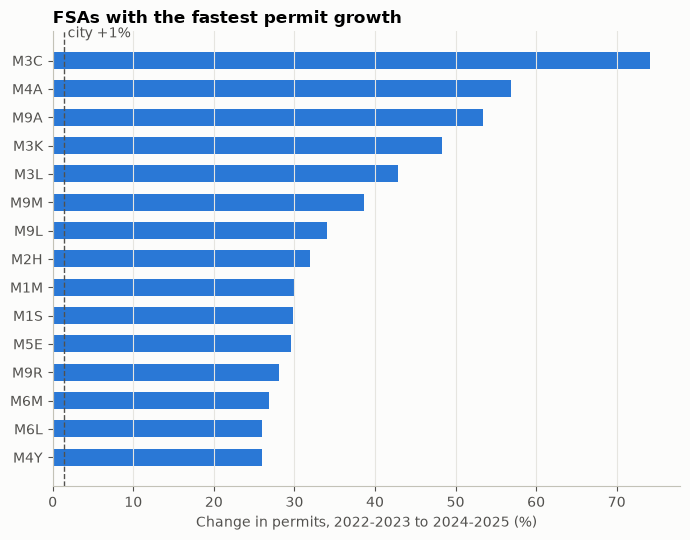

In [8]:
plot = top_growth.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(plot.index, plot["growth_pct"], color=PALETTE[0], height=0.6)
ax.axvline(city_growth, color="#52514e", linewidth=1, linestyle="--")
ax.text(city_growth, len(plot) - 0.3, f" city {city_growth:+.0f}%", color="#52514e", va="bottom")
ax.set_xlabel(f"Change in permits, {BASE[0]}-{BASE[1]} to {RECENT[0]}-{RECENT[1]} (%)")
ax.set_title("FSAs with the fastest permit growth")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGS / "q1_fsa_growth.png", dpi=150)
plt.show()

## Q2. What kind of work is it?

Split by sector (residential, non-residential, mixed use) and work category, by permit count and by declared value, over the full period and year by year.

In [9]:
full = demand[demand["app_year"].isin(FULL_YEARS)]

mix_count = pd.crosstab(full["sector"], full["work_category"], margins=True, margins_name="Total")
mix_value = full.pivot_table(index="sector", columns="work_category", values="declared_value",
                             aggfunc="sum", margins=True, margins_name="Total") / 1e6

print("Permits by sector and work category:")
display(mix_count)
print("Declared value ($ millions):")
display(mix_value)

share_count = (mix_count / mix_count.loc["Total", "Total"] * 100).round(1)
share_value = (mix_value / mix_value.loc["Total", "Total"] * 100).round(1)
print("Share of permits (%):")
display(share_count)
print("Share of declared value (%):")
display(share_value)

save_table(mix_count, "q2_mix_permits")
save_table(mix_value, "q2_mix_value_millions")

Permits by sector and work category:


work_category,Addition,Building services,Demolition,New construction,Other,Renovation / alteration,Total
sector,,,,,,,
Mixed use,0,231,163,868,3,8,1273
Non-residential,428,9224,1002,1200,1369,27709,40932
Residential,11112,29429,8599,15519,6846,49634,121139
Unknown,44,494,165,166,10386,1045,12300
Total,11584,39378,9929,17753,18604,78396,175644


Declared value ($ millions):


work_category,Addition,Building services,Demolition,New construction,Other,Renovation / alteration,Total
sector,,,,,,,
Mixed use,NaN,644.6,2.7,"18,607.8",0.0,0.0,"19,255.1"
Non-residential,"1,004.3","3,191.4",89.4,"15,877.5",116.2,"14,353.3","34,632.2"
Residential,590.0,"1,722.2",63.6,"20,388.8",141.9,"7,721.5","30,628.0"
Unknown,15.9,350.2,4.4,885.2,17.2,887.6,"2,160.5"
Total,"1,610.2","5,908.5",160.1,"55,759.3",275.3,"22,962.4","86,675.8"


Share of permits (%):


work_category,Addition,Building services,Demolition,New construction,Other,Renovation / alteration,Total
sector,,,,,,,
Mixed use,0.0,0.1,0.1,0.5,0.0,0.0,0.7
Non-residential,0.2,5.3,0.6,0.7,0.8,15.8,23.3
Residential,6.3,16.8,4.9,8.8,3.9,28.3,69.0
Unknown,0.0,0.3,0.1,0.1,5.9,0.6,7.0
Total,6.6,22.4,5.7,10.1,10.6,44.6,100.0


Share of declared value (%):


work_category,Addition,Building services,Demolition,New construction,Other,Renovation / alteration,Total
sector,,,,,,,
Mixed use,NaN,0.7,0.0,21.5,0.0,0.0,22.2
Non-residential,1.2,3.7,0.1,18.3,0.1,16.6,40.0
Residential,0.7,2.0,0.1,23.5,0.2,8.9,35.3
Unknown,0.0,0.4,0.0,1.0,0.0,1.0,2.5
Total,1.9,6.8,0.2,64.3,0.3,26.5,100.0


saved outputs/summary_tables/q2_mix_permits.csv (5 rows)
saved outputs/summary_tables/q2_mix_value_millions.csv (5 rows)


In [10]:
# How the work mix changes year to year (share of each year's permits).
mix_year = pd.crosstab(full["app_year"], full["work_category"], normalize="index") * 100
display(mix_year.round(1))
save_table(mix_year, "q2_work_mix_by_year_pct")

# Residential share of permits and of value, by year.
res = full.groupby("app_year").apply(lambda g: pd.Series({
    "residential_permit_share_pct": (g["sector"] == "Residential").mean() * 100,
    "residential_value_share_pct": g.loc[g["sector"] == "Residential", "declared_value"].sum()
                                   / g["declared_value"].sum() * 100,
}), include_groups=False)
display(res.round(1))
save_table(res, "q2_residential_share_by_year")

work_category,Addition,Building services,Demolition,New construction,Other,Renovation / alteration
app_year,,,,,,
2017,6.1,26.3,5.3,9.3,11.6,41.3
2018,6.1,27.5,5.7,9.3,10.7,40.7
2019,5.9,23.8,5.1,10.1,11.0,44.0
2020,7.8,22.3,5.2,8.8,11.9,44.0
2021,7.9,20.4,6.0,9.9,10.8,44.9
2022,6.7,20.5,6.6,9.2,9.8,47.2
2023,5.9,18.7,6.1,12.4,9.2,47.7
2024,6.5,19.2,5.9,10.8,9.7,47.9
2025,6.7,19.6,5.2,11.9,9.9,46.7


saved outputs/summary_tables/q2_work_mix_by_year_pct.csv (9 rows)


,residential_permit_share_pct,residential_value_share_pct
app_year,,
2017,66.5,42.5
2018,68.2,50.0
2019,68.4,46.0
2020,72.7,46.0
2021,72.5,40.8
2022,70.6,41.5
2023,68.4,20.1
2024,67.1,31.1
2025,67.4,27.7


saved outputs/summary_tables/q2_residential_share_by_year.csv (9 rows)


## Q3. How long do permits take from application to issuance?

Only issued, non-revised permits (revision rows can carry a later application date). We report the median and the middle 50% range (25th to 75th percentile), because a few permits take years.

**Important bias:** for recent application years, permits that are still waiting are not in the data yet as issued. Only the fast ones have finished, so recent years will look faster than they really are. The year table shows the share still not issued so this is visible.

In [11]:
issued = demand[demand["approval_days"].notna() & ~demand["is_revision"]]
print(f"Issued, non-revised demand permits: {len(issued):,}")

def approval_summary(df, by, min_n=100):
    out = df.groupby(by)["approval_days"].agg(
        permits="count",
        median="median",
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
        p90=lambda s: s.quantile(0.90),
    )
    return out[out["permits"] >= min_n].sort_values("median")

by_cat = approval_summary(issued, "work_category")
by_sector = approval_summary(issued, "sector")
by_type = approval_summary(issued, "PERMIT_TYPE")
print("By work category:"); display(by_cat)
print("By sector:"); display(by_sector)
print("By permit type (min 100 permits):"); display(by_type)
save_table(by_cat, "q3_approval_by_work_category")
save_table(by_sector, "q3_approval_by_sector")
save_table(by_type, "q3_approval_by_permit_type")

Issued, non-revised demand permits: 157,490
By work category:


,permits,median,p25,p75,p90
work_category,,,,,
Building services,40362,4.0,0.0,25.0,40.0
Other,16754,15.0,7.0,37.0,90.0
Addition,10336,26.0,9.0,71.0,207.0
Renovation / alteration,68257,27.0,12.0,49.0,98.0
Demolition,10130,57.0,32.0,112.0,239.0
New construction,11651,83.0,40.0,237.0,546.0


By sector:


,permits,median,p25,p75,p90
sector,,,,,
Unknown,10776,20.0,9.0,49.0,120.0
Residential,108659,20.0,6.0,50.0,131.0
Non-residential,37476,29.0,15.0,49.0,98.0
Mixed use,579,285.0,97.0,731.5,"1,255.4"


By permit type (min 100 permits):


,permits,median,p25,p75,p90
PERMIT_TYPE,,,,,
Drain and Site Service,23505,0.0,0.0,3.0,11.0
Temporary Structures,2386,10.0,4.0,19.0,34.0
Small Residential Projects,51289,19.0,8.0,49.0,118.0
Designated Structures,8050,20.0,10.0,51.0,118.1
Plumbing(PS),8106,24.0,12.0,33.0,49.0
Fire/Security Upgrade,6460,26.0,8.0,34.0,53.0
Mechanical(MS),2197,29.0,17.0,40.0,74.4
Building Additions/Alterations,34808,31.0,17.0,54.0,102.0
Portable Classrooms,184,41.5,30.0,67.0,110.7


saved outputs/summary_tables/q3_approval_by_work_category.csv (6 rows)
saved outputs/summary_tables/q3_approval_by_sector.csv (4 rows)
saved outputs/summary_tables/q3_approval_by_permit_type.csv (14 rows)


In [12]:
# By application year, with the share of that year's permits not yet issued.
by_year = approval_summary(issued, "app_year", min_n=1).sort_index()
not_issued = (demand[~demand["is_revision"]].groupby("app_year")["ISSUED_DATE"]
              .apply(lambda s: s.isna().mean() * 100).rename("not_yet_issued_pct"))
by_year = by_year.join(not_issued)
display(by_year)
save_table(by_year, "q3_approval_by_year")

,permits,median,p25,p75,p90,not_yet_issued_pct
app_year,,,,,,
2017,21083,19.0,6.0,42.0,110.8,1.3
2018,20415,20.0,7.0,41.0,104.0,1.8
2019,18919,23.0,7.0,49.0,140.0,2.2
2020,14033,26.0,9.0,56.0,132.0,6.1
2021,15943,28.0,11.0,60.0,145.0,4.9
2022,15569,32.0,12.0,70.0,168.0,3.7
2023,13279,28.0,8.0,64.0,141.0,4.6
2024,13592,19.0,6.0,49.0,113.0,5.2
2025,14392,22.0,7.0,48.0,107.0,6.8


saved outputs/summary_tables/q3_approval_by_year.csv (10 rows)


In [13]:
# By FSA. Work type drives approval time, so compare FSAs within the two
# largest categories rather than mixing a new tower with a deck permit.
fsa_rows = []
for cat in ["Renovation / alteration", "New construction"]:
    t = approval_summary(issued[issued["work_category"] == cat], "fsa", min_n=30)
    t["work_category"] = cat
    fsa_rows.append(t)
by_fsa = pd.concat(fsa_rows)
save_table(by_fsa, "q3_approval_by_fsa")

for cat in ["Renovation / alteration", "New construction"]:
    t = by_fsa[by_fsa["work_category"] == cat]
    print(f"{cat}: {len(t)} FSAs with 30+ permits, "
          f"median ranges from {t['median'].min():.0f} to {t['median'].max():.0f} days")
    display(pd.concat([t.head(5), t.tail(5)])[["permits", "median", "p25", "p75"]])

saved outputs/summary_tables/q3_approval_by_fsa.csv (174 rows)
Renovation / alteration: 98 FSAs with 30+ permits, median ranges from 15 to 38 days


,permits,median,p25,p75
fsa,,,,
M1C,683,15.0,8.0,49.0
M5X,91,16.0,7.5,28.0
M1X,226,17.0,8.0,46.0
M6S,1326,18.0,8.0,40.0
M4T,645,19.0,9.0,34.0
M3K,148,36.0,16.0,71.0
M9M,220,36.0,15.8,77.0
M9N,400,36.0,15.0,75.0
M9V,547,36.0,14.0,76.0


New construction: 76 FSAs with 30+ permits, median ranges from 20 to 1738 days


,permits,median,p25,p75
fsa,,,,
M6K,61,20.0,20.0,97.0
M5N,136,35.0,23.0,62.0
M4N,112,41.0,26.8,65.8
M8X,77,46.0,21.0,81.0
M3B,155,47.0,33.0,79.0
M3C,161,233.0,161.0,238.0
M6R,89,243.0,71.0,399.0
M6A,429,263.0,56.0,589.0
M3K,82,273.5,91.5,300.0


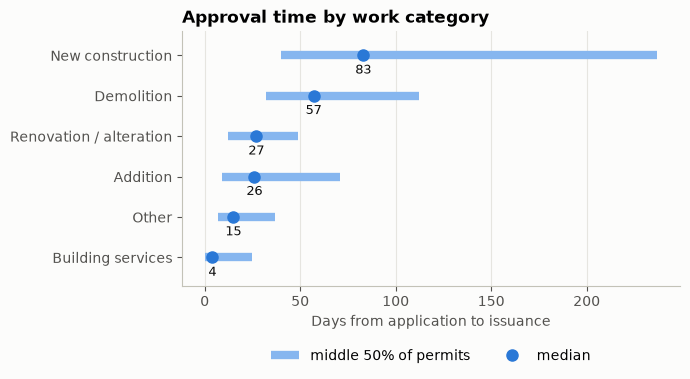

In [14]:
plot = by_cat.sort_values("median")
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(plot))
ax.hlines(y, plot["p25"], plot["p75"], color="#86b6ef", linewidth=6, label="middle 50% of permits")
ax.plot(plot["median"], y, "o", color=PALETTE[0], markersize=8, label="median")
for yi, m in zip(y, plot["median"]):
    ax.text(m, yi - 0.22, f"{m:.0f}", ha="center", va="top", color="#0b0b0b", fontsize=9)
ax.set_yticks(y, plot.index)
ax.set_xlabel("Days from application to issuance")
ax.set_title("Approval time by work category")
ax.set_ylim(-0.7, len(plot) - 0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGS / "q3_approval_by_category.png", dpi=150)
plt.show()

## Q4. How have volumes and values changed, and is there a seasonal pattern?

In [15]:
annual = full.groupby("app_year").agg(
    permits=("PERMIT_NUM", "count"),
    declared_value_millions=("declared_value", lambda s: s.sum() / 1e6),
    median_declared_cost=("declared_value", "median"),
    new_construction=("work_category", lambda s: (s == "New construction").sum()),
)
annual["permits_yoy_pct"] = annual["permits"].pct_change() * 100
annual["value_yoy_pct"] = annual["declared_value_millions"].pct_change() * 100
display(annual)
save_table(annual, "q4_annual_totals")

,permits,declared_value_millions,median_declared_cost,new_construction,permits_yoy_pct,value_yoy_pct
app_year,,,,,,
2017,23804,"6,844.7","50,000.0",2218,NaN,NaN
2018,23220,"6,663.0","50,000.0",2161,-2.5,-2.7
2019,22331,"7,791.0","50,000.0",2248,-3.8,16.9
2020,17206,"4,342.1","50,000.0",1509,-23.0,-44.3
2021,19271,"8,491.6","60,000.0",1913,12.0,95.6
2022,18489,"8,638.6","64,000.0",1697,-4.1,1.7
2023,16246,"12,142.7","75,000.0",2022,-12.1,40.6
2024,16968,"14,903.6","75,000.0",1839,4.4,22.7
2025,18109,"16,858.6","55,000.0",2146,6.7,13.1


saved outputs/summary_tables/q4_annual_totals.csv (9 rows)


In [16]:
# Monthly permits by work category (full months only), for trend charts.
monthly = (demand[demand["app_year_month"] <= LAST_FULL_MONTH]
           .pivot_table(index="app_year_month", columns="work_category",
                        values="PERMIT_NUM", aggfunc="count", fill_value=0))
save_table(monthly, "q4_monthly_by_work_category")

# Seasonality: each month's share of its year's permits, averaged over full
# years. Index 100 = an average month; 120 = 20% busier than average.
m = full.groupby(["app_year", "app_month"]).size().rename("permits").reset_index()
m["index"] = m["permits"] / m.groupby("app_year")["permits"].transform("mean") * 100
season = m.groupby("app_month")["index"].agg(["mean", "min", "max"]).round(1)
season.index = pd.to_datetime(season.index, format="%m").strftime("%b")
display(season)
save_table(season, "q4_seasonality_index")

saved outputs/summary_tables/q4_monthly_by_work_category.csv (117 rows)


,mean,min,max
app_month,,,
Jan,85.3,74.2,96.7
Feb,88.0,72.3,107.1
Mar,99.4,63.4,115.7
Apr,101.0,66.1,112.4
May,112.4,80.6,129.4
Jun,110.4,96.6,126.3
Jul,107.3,96.3,122.9
Aug,110.9,93.8,118.9
Sep,104.1,98.1,117.0


saved outputs/summary_tables/q4_seasonality_index.csv (12 rows)


Average monthly permits: 1,626
Seasonal swing (peak month minus low month): 514 permits


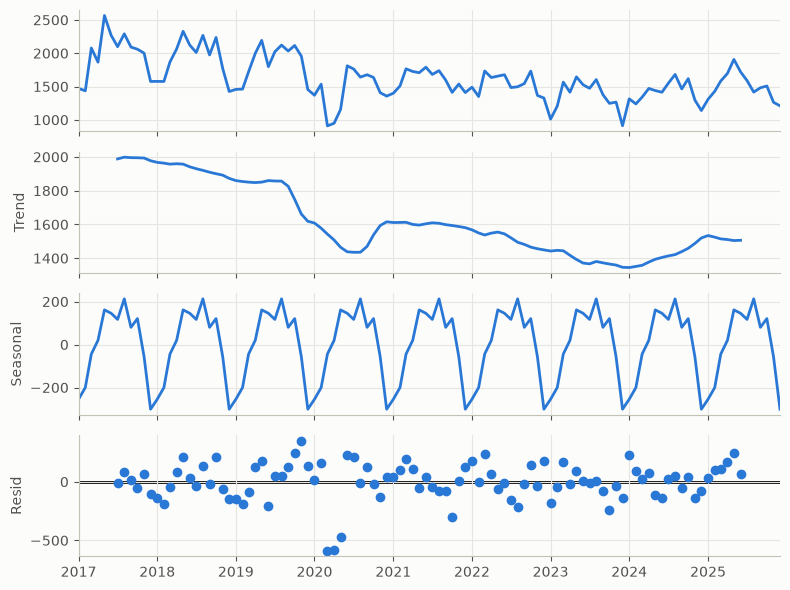

In [17]:
# A second view of seasonality: classical decomposition of the monthly total
# into trend + repeating 12-month pattern + leftover noise. If the seasonal
# swing is small relative to the trend, seasonality matters less for planning.
total_monthly = monthly.sum(axis=1)
total_monthly = total_monthly[total_monthly.index.year.isin(FULL_YEARS)]
decomp = seasonal_decompose(total_monthly, model="additive", period=12)

seasonal_range = decomp.seasonal.max() - decomp.seasonal.min()
print(f"Average monthly permits: {total_monthly.mean():,.0f}")
print(f"Seasonal swing (peak month minus low month): {seasonal_range:,.0f} permits")

fig = decomp.plot()
fig.set_size_inches(8, 6)
fig.tight_layout()
fig.savefig(FIGS / "q4_seasonal_decomposition.png", dpi=150)
plt.show()

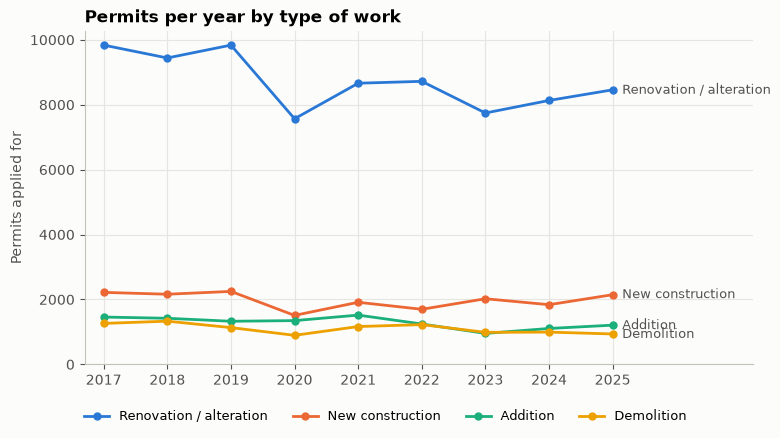

In [18]:
# Annual permits by work category. Building services and Other are left out
# to keep the chart readable; they are in the saved table.
cats = ["Renovation / alteration", "New construction", "Addition", "Demolition"]
yearly = pd.crosstab(full["app_year"], full["work_category"])[cats]

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, cat in enumerate(cats):
    ax.plot(yearly.index, yearly[cat], color=PALETTE[i], marker="o", markersize=5, label=cat)
    ax.text(yearly.index[-1] + 0.15, yearly[cat].iloc[-1], cat, color="#52514e", va="center", fontsize=9)
ax.set_xlim(yearly.index[0] - 0.3, yearly.index[-1] + 2.2)
ax.set_xticks(yearly.index)
ax.set_ylim(0)
ax.set_ylabel("Permits applied for")
ax.set_title("Permits per year by type of work")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "q4_annual_by_work_category.png", dpi=150)
plt.show()

## Table for Tableau

One row per FSA, month, sector and work category, with permit count, declared value and median approval days. This is the main data source for the Share phase dashboard (map, monthly trend, approval times, growth areas).

In [19]:
tableau = (demand[demand["fsa"].notna() & (demand["app_year_month"] <= LAST_FULL_MONTH)]
           .groupby(["fsa", "app_year_month", "sector", "work_category"])
           .agg(permits=("PERMIT_NUM", "count"),
                declared_value=("declared_value", "sum"),
                permits_with_value=("cost_declared", "sum"),
                median_approval_days=("approval_days", "median"))
           .reset_index())
tableau.to_csv(TABLES / "tableau_fsa_month.csv", index=False)
print(f"saved outputs/summary_tables/tableau_fsa_month.csv ({len(tableau):,} rows)")

saved outputs/summary_tables/tableau_fsa_month.csv (61,972 rows)


## Key numbers for the findings summary

In [20]:
fastest = top_growth.head(3)
print(f"Analysis set: {len(demand):,} demand permits, {FULL_YEARS[0]}-{FULL_YEARS[-1]} full years")
print(f"City-wide permit change {BASE} -> {RECENT}: {city_growth:+.1f}%")
print(f"Top 10 FSAs share of recent declared value: {top10_share:.1f}%")
print("Fastest-growing FSAs:", ", ".join(f"{i} ({g:+.0f}%)" for i, g in fastest["growth_pct"].items()))
print(f"Residential share of permits, full period: {share_count.loc['Residential', 'Total']:.1f}%")
print(f"Residential share of value, full period:   {share_value.loc['Residential', 'Total']:.1f}%")
print("Median approval days by category:", ", ".join(f"{c} {d:.0f}" for c, d in by_cat["median"].items()))
busiest = season["mean"].idxmax(); quietest = season["mean"].idxmin()
print(f"Busiest month: {busiest} (index {season['mean'].max():.0f}); quietest: {quietest} (index {season['mean'].min():.0f})")

Analysis set: 191,381 demand permits, 2017-2025 full years
City-wide permit change [2022, 2023] -> [2024, 2025]: +1.4%
Top 10 FSAs share of recent declared value: 43.3%
Fastest-growing FSAs: M3C (+74%), M4A (+57%), M9A (+53%)
Residential share of permits, full period: 69.0%
Residential share of value, full period:   35.3%
Median approval days by category: Building services 4, Other 15, Addition 26, Renovation / alteration 27, Demolition 57, New construction 83
Busiest month: May (index 112); quietest: Dec (index 81)
